<a href="https://colab.research.google.com/github/ortizo-117/BMEG_591Q_group_project/blob/master/Lab_B_Pt3_clean.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BMEG 400Q/591Q: Lab B - Part 3

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path_to_data = "/content/drive/MyDrive/BMEG591Q-Data" #TO-DO: link the path to your dataset here.

In [ ]:
import os, math, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
try:
    import pandas as pd
except Exception:
    !pip -q install pandas
    import pandas as pd
import numpy as np

### Section 1: Graph-Cut Segmentation

using OpenCV’s GrabCut (graph cut under the hood), supports auto-seeding (so no clicking needed), and computes overlap-based (Dice/IoU/Precision/Recall) and distance-based (ASSD, Hausdorff, Hausdorff95) metrics.

In [ ]:
# ---- Dependencies (install if needed) ----
try:
    import cv2
except Exception:
    !pip -q install opencv-python-headless
    import cv2

try:
    from skimage import img_as_ubyte
    from skimage.filters import threshold_otsu
    from skimage.morphology import binary_opening, binary_closing, disk, remove_small_objects
    from skimage.segmentation import find_boundaries
    from skimage.measure import label, regionprops
except Exception:
    !pip -q install scikit-image
    from skimage import img_as_ubyte
    from skimage.filters import threshold_otsu
    from skimage.morphology import binary_opening, binary_closing, disk, remove_small_objects
    from skimage.segmentation import find_boundaries
    from skimage.measure import label, regionprops

try:
    from scipy.ndimage import distance_transform_edt
except Exception:
    !pip -q install scipy
    from scipy.ndimage import distance_transform_edt

In [ ]:
# -----------------------
# 0) Paths & Image Load
# -----------------------

try:
    path_to_data
except NameError:
    path_to_data = "."

IMG_PATH = os.path.join(path_to_data, "cttest.png")
if not Path(IMG_PATH).exists():
    print(f"Image not found at {IMG_PATH}. Please upload cttest.png when prompted.")
    try:
        from google.colab import files
        up = files.upload()
        if "cttest.png" in up:
            IMG_PATH = "cttest.png"
        else:
            # use first uploaded file
            IMG_PATH = list(up.keys())[0]
        print(f"Using: {IMG_PATH}")
    except Exception as e:
        raise FileNotFoundError("No image provided.") from e

img_raw = cv2.imread(IMG_PATH, cv2.IMREAD_UNCHANGED)
if img_raw is None:
    raise ValueError(f"Failed to read image at {IMG_PATH}")

In [ ]:
# Grayscale
if img_raw.ndim == 3:
    img_gray = cv2.cvtColor(img_raw, cv2.COLOR_BGR2GRAY)
else:
    img_gray = img_raw.copy()

# Robust window -> float [0,1] and uint8 for CV ops
p_lo, p_hi = np.percentile(img_gray.astype(np.float32), (0.5, 99.5))
xf = np.clip(img_gray.astype(np.float32), p_lo, p_hi)
xf = (xf - p_lo) / max(p_hi - p_lo, 1e-6)
x8 = img_as_ubyte(xf)  # 0..255

H, W = x8.shape

In [ ]:
# -----------------------
# 1) Utility: Display
# -----------------------
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 160
mpl.rcParams['axes.titlesize'] = 9

def overlay_boundary(base_float01, mask_bool, title):
    bd = find_boundaries(mask_bool, mode='outer')
    img = (base_float01 - base_float01.min()) / (np.ptp(base_float01) + 1e-6)
    rgb = np.dstack([img, img, img])
    rgb[bd] = [1, 0, 0]
    plt.imshow(rgb, interpolation='nearest')
    plt.title(title); plt.axis('off')

In [ ]:
# -----------------------
# 2) Auto-seeding for GrabCut
#    (A) Rectangle init around thorax
#    (B) Mask init via Otsu FG/BG priors
# -----------------------
def auto_rect(x8, margin_frac=0.06):
    """Rectangle around central thorax region to initialize GrabCut."""
    m = margin_frac
    r0 = int(H*m); r1 = int(H*(1-m))
    c0 = int(W*m); c1 = int(W*(1-m))
    return (c0, r0, c1-c0, r1-r0)  # OpenCV rect = (x, y, w, h)


def auto_seed_mask_from_otsu(x8, hi_pct=95, open_r=2, close_r=3, small_rm=200):
    """
    Build an initial GrabCut mask with Otsu-based FG/BG priors.
    - air (dark) -> probable FG
    - very bright -> sure BG
    - darkest core of air -> sure FG
    """
    thr = threshold_otsu(x8)
    air = x8 < thr  # lungs
    air = binary_opening(air, disk(open_r))
    air = binary_closing(air, disk(close_r))
    air = remove_small_objects(air, small_rm)

    hi_thr = np.percentile(x8, hi_pct)
    bright = x8 >= hi_thr

    gc_mask = np.full(x8.shape, 1, np.uint8)  # probable BG
    gc_mask[bright] = 0                       # sure BG
    gc_mask[air] = 2                          # probable FG

    if air.any():
        core_thr = np.percentile(x8[air], 2)
        core = x8 <= core_thr
        gc_mask[core] = 3                     # sure FG
    return gc_mask

In [ ]:
# -----------------------
# 3) Graph-Cut via GrabCut
# -----------------------
def run_grabcut_rect(x_bgr_or_gray, rect, iters=5):
    """
    GrabCut with rectangle init. If grayscale, convert to BGR for OpenCV.
    """
    if x_bgr_or_gray.ndim == 2:
        X = cv2.cvtColor(x_bgr_or_gray, cv2.COLOR_GRAY2BGR)
    else:
        X = x_bgr_or_gray.copy()

    mask = np.zeros(X.shape[:2], np.uint8)
    bgdModel = np.zeros((1, 65), np.float64)
    fgdModel = np.zeros((1, 65), np.float64)
    cv2.grabCut(X, mask, rect, bgdModel, fgdModel, iters, cv2.GC_INIT_WITH_RECT)
    # FG = {prob FG, sure FG}
    seg = np.logical_or(mask == cv2.GC_FGD, mask == cv2.GC_PR_FGD)
    return seg.astype(bool)

def run_grabcut_mask(x_bgr_or_gray, gc_mask_init, iters=5):
    if x_bgr_or_gray.ndim == 2:
        X = cv2.cvtColor(x_bgr_or_gray, cv2.COLOR_GRAY2BGR)
    else:
        X = x_bgr_or_gray.copy()

    mask = gc_mask_init.copy()
    bgdModel = np.zeros((1, 65), np.float64)
    fgdModel = np.zeros((1, 65), np.float64)
    cv2.grabCut(X, mask, None, bgdModel, fgdModel, iters, cv2.GC_INIT_WITH_MASK)
    seg = np.logical_or(mask == cv2.GC_FGD, mask == cv2.GC_PR_FGD)
    return seg.astype(bool)


In [ ]:
# -----------------------
# 4) Reference (Ground Truth) Handling
# -----------------------
def load_or_make_reference(x8):
    """
    Build a surrogate lung mask from Otsu + morphology.
    """

    thr = threshold_otsu(x8)
    gt = x8 < thr  # lungs (air) are dark
    gt = binary_opening(gt, disk(3))
    gt = binary_closing(gt, disk(5))
    gt = remove_small_objects(gt, 500)
    # Keep two largest components (two lungs) if present
    lab = label(gt)
    if lab.max() >= 2:
        areas = [(i, (lab == i).sum()) for i in range(1, lab.max()+1)]
        areas.sort(key=lambda t: t[1], reverse=True)
        keep_ids = [i for i,_ in areas[:2]]
        gt = np.isin(lab, keep_ids)
    src = "Surrogate GT (Otsu+morph)"

    return gt.astype(bool), src

GT_MASK, GT_SRC = load_or_make_reference(x8)

In [ ]:
# -----------------------
# 5) Metrics
# -----------------------
#Some functions to write in this block.

def dice_coef(a, b):
    #TO-DO: write this func
    #dice_c = 2 * (a & b).sum() / (a.sum() + b.sum())


    intersect = np.sum(b*a)
    total_sum = np.sum(a) + np.sum(b)
    dice_c = np.mean(2*intersect / total_sum)

    return dice_c

def jaccard_iou(a, b):
    #TO-DO: write this func
    intersect = np.sum(b*a)
    union = np.sum(a) + np.sum(b) - intersect
    iou = np.mean(intersect / union)
    return iou


def precision(a, b):
    # a = prediction, b = reference
    #TO-DO: write this func
    intersect = np.sum(b*a)
    total_pixel_pred = np.sum(a)
    precision = np.mean(intersect / total_pixel_pred)
    return round(precision,3)


def recall(a, b):

    #TO-DO: write this func
    intersect = np.sum(b*a)
    total_pixel_ref = np.sum(b)
    recall = np.mean(intersect / total_pixel_ref)
    return round(recall,3)


def surface_distances(a, b):
    """
    Compute symmetric surface distances between binary masks a (pred) and b (ref).
    Returns ASSD (average symmetric surface distance), Hausdorff, Hausdorff95.
    """
    a = a.astype(bool); b = b.astype(bool)
    if a.sum()==0 or b.sum()==0:
        return np.inf, np.inf, np.inf

    # surfaces
    a_bd = find_boundaries(a, mode='outer')
    b_bd = find_boundaries(b, mode='outer')

    # distance maps to the opposite surface
    # distance inside the complement gives distance to nearest True boundary
    dt_a = distance_transform_edt(~a_bd)
    dt_b = distance_transform_edt(~b_bd)

    # distances from each surface pixel in A to B and vice versa
    d_a2b = dt_b[a_bd]
    d_b2a = dt_a[b_bd]

    # symmetric set of distances
    all_d = np.concatenate([d_a2b, d_b2a]).astype(np.float64)
    if all_d.size == 0:
        return 0.0, 0.0, 0.0

    assd = all_d.mean()
    hd = all_d.max()
    #TO-DO: 95th percentile
    hd95 = np.percentile(all_d, 95)

    return assd, hd, hd95


In [ ]:
# -----------------------
# 6) Run Graph-Cut Variants
# -----------------------
rect = auto_rect(x8, margin_frac=0.06)

#gc_mask_init, air_prior = auto_seed_mask_from_otsu(x8, small_rm=200)
gc_mask_init = auto_seed_mask_from_otsu(x8, small_rm=200)


seg_rect = run_grabcut_rect(x8, rect, iters=5)
seg_mask = run_grabcut_mask(x8, gc_mask_init, iters=5)

In [ ]:
# -----------------------
# 7) Evaluate
# -----------------------
def eval_metrics(pred, ref):
    return {
        "Dice": dice_coef(pred, ref),
        "IoU": jaccard_iou(pred, ref),
        "Precision": precision(pred, ref),
        "Recall": recall(pred, ref),
        **(lambda a: {"ASSD": a[0], "HD": a[1], "HD95": a[2]})(surface_distances(pred, ref))
    }

def evaluate_and_print(pred, ref, name):
    d = dice_coef(pred, ref)
    j = jaccard_iou(pred, ref)
    p = precision(pred, ref)
    r = recall(pred, ref)
    assd, hd, hd95 = surface_distances(pred, ref)
    print(f"[{name}] vs {GT_SRC}")
    print(f"  Dice: {d:.4f} | IoU: {j:.4f} | Precision: {p:.4f} | Recall: {r:.4f}")
    print(f"  ASSD: {assd:.3f} px | Hausdorff: {hd:.3f} px | HD95: {hd95:.3f} px\n")
    return dict(Dice=d, IoU=j, Precision=p, Recall=r, ASSD=assd, HD=hd, HD95=hd95)

In [ ]:
m_rect = evaluate_and_print(seg_rect, GT_MASK, "GrabCut-Rect")
m_mask = evaluate_and_print(seg_mask, GT_MASK, "GrabCut-Mask(Otsu-seeded)")


[GrabCut-Rect] vs Surrogate GT (Otsu+morph)
  Dice: 0.2980 | IoU: 0.1751 | Precision: 0.3060 | Recall: 0.2900
  ASSD: 32.746 px | Hausdorff: 122.000 px | HD95: 93.030 px

[GrabCut-Mask(Otsu-seeded)] vs Surrogate GT (Otsu+morph)
  Dice: 0.0632 | IoU: 0.0326 | Precision: 0.0760 | Recall: 0.0540
  ASSD: 14.907 px | Hausdorff: 76.903 px | HD95: 51.805 px



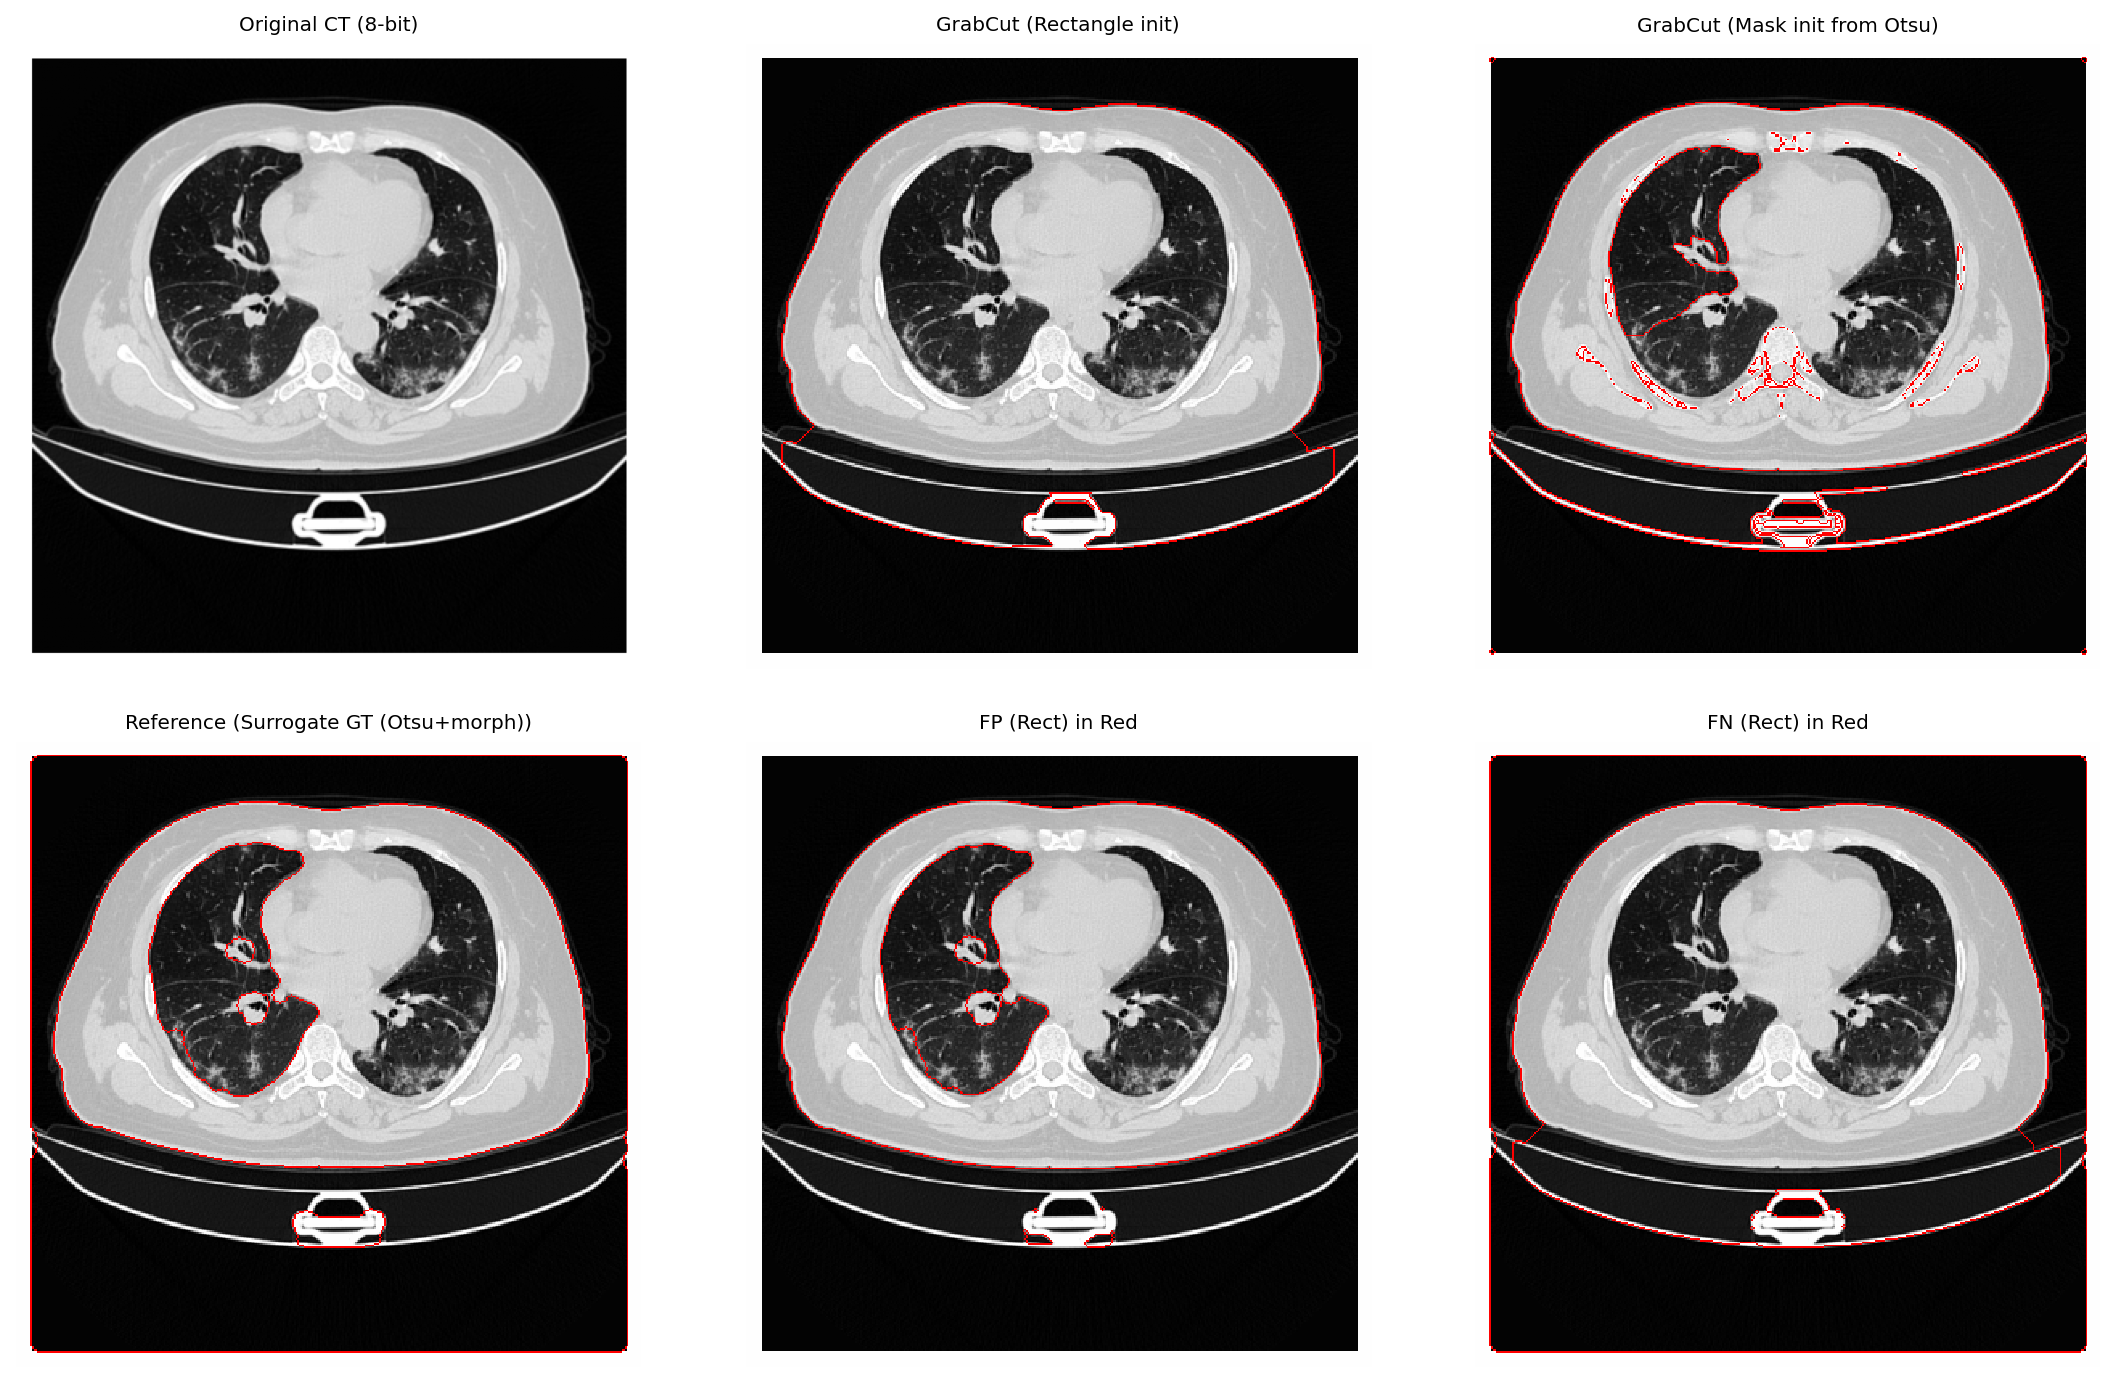

In [ ]:
# -----------------------
# 8) Visualize
# -----------------------
plt.figure(figsize=(14, 9))

plt.subplot(2,3,1); plt.imshow(x8, cmap='gray'); plt.title("Original CT (8-bit)"); plt.axis('off')

plt.subplot(2,3,2); overlay_boundary(xf, seg_rect, "GrabCut (Rectangle init)")
plt.subplot(2,3,3); overlay_boundary(xf, seg_mask, "GrabCut (Mask init from Otsu)")

plt.subplot(2,3,4); overlay_boundary(xf, GT_MASK, f"Reference ({GT_SRC})")
plt.subplot(2,3,5); overlay_boundary(xf, np.logical_and(seg_rect, ~GT_MASK), "FP (Rect) in Red")
plt.subplot(2,3,6); overlay_boundary(xf, np.logical_and(GT_MASK, ~seg_rect), "FN (Rect) in Red")

plt.tight_layout(pad=2.0, w_pad=2.0, h_pad=2.0)
plt.show()

In [ ]:
# -----------------------
# 9) Student prompts (print-only)
# -----------------------
print("Try-it prompts:")
print("  • Change the rectangle margin in auto_rect(margin_frac) and rerun GrabCut-Rect.")
print("  • Change Otsu priors in auto_seed_mask_from_otsu (percentiles, morphology radii).")
print("  • Compare metrics between Rect vs Mask initializations. Which has better Dice/HD95?")
print("  • (If you have a manual GT mask at cttest_lung_gt.png) replace the surrogate and re-evaluate.")

##### Parameter Sweeps

In [ ]:
import itertools

In [ ]:
# --- Small helper that wraps existing metrics ---
def eval_metrics(pred, ref):
    return {
        "Dice":        float(dice_coef(pred, ref)),
        "IoU":         float(jaccard_iou(pred, ref)),
        "Precision":   float(precision(pred, ref)),
        "Recall":      float(recall(pred, ref)),
        **(lambda a: {"ASSD": float(a[0]), "HD": float(a[1]), "HD95": float(a[2])})(surface_distances(pred, ref))
    }

def get_seg_from_row(row):
    if row["Method"] == "GrabCut-Rect":
        rect = auto_rect(x8, margin_frac=row["margin_frac"])
        return run_grabcut_rect(x8, rect, iters=int(row["iters"]))
    else:
        gc_mask = auto_seed_mask_from_otsu(x8,
                                           hi_pct=int(row["hi_pct"]),
                                           open_r=int(row["open_r"]),
                                           close_r=int(row["close_r"]),
                                           small_rm=int(row["small_rm"]))
        return run_grabcut_mask(x8, gc_mask, iters=int(row["iters"]))

In [ ]:
# -----------------------
# Sweep definitions (tweak as desired)
# -----------------------
RECT_SWEEP = {
    "margin_frac": [0.04, 0.06, 0.08, 0.10],
    "iters": [3, 5, 8],
}

MASK_SWEEP = {
    "hi_pct": [93, 95, 97],   # percentile for "sure BG" brightness
    "open_r": [1, 2, 3],      # opening radius on air prior
    "close_r": [3],           # keep short to contain runtime
    "small_rm": [200],        # remove tiny air specks
    "iters": [5],             # GrabCut iterations
}

In [ ]:
# -----------------------
# Run sweeps
# -----------------------
results = []

# (A) GrabCut-Rect sweep
for m, it in itertools.product(RECT_SWEEP["margin_frac"], RECT_SWEEP["iters"]):
    rect = auto_rect(x8, margin_frac=m)
    seg = run_grabcut_rect(x8, rect, iters=it)
    met = eval_metrics(seg, GT_MASK)
    results.append({
        "Method": "GrabCut-Rect",
        "margin_frac": m, "iters": it,
        "hi_pct": None, "open_r": None, "close_r": None, "small_rm": None,
        **met
    })

# (B) GrabCut-Mask (Otsu-seeded) sweep
for hp, op, cp, rm, it in itertools.product(
    MASK_SWEEP["hi_pct"], MASK_SWEEP["open_r"], MASK_SWEEP["close_r"], MASK_SWEEP["small_rm"], MASK_SWEEP["iters"]
):
    gc_mask = auto_seed_mask_from_otsu(x8, hi_pct=hp, open_r=op, close_r=cp, small_rm=rm)
    seg = run_grabcut_mask(x8, gc_mask, iters=it)
    met = eval_metrics(seg, GT_MASK)
    results.append({
        "Method": "GrabCut-Mask",
        "margin_frac": None, "iters": it,
        "hi_pct": hp, "open_r": op, "close_r": cp, "small_rm": rm,
        **met
    })

In [ ]:
df = pd.DataFrame(results)
display_cols = ["Method","margin_frac","iters","hi_pct","open_r","close_r","small_rm",
                "Dice","IoU","Precision","Recall","ASSD","HD","HD95"]
df = df[display_cols].sort_values(["Method","Dice"], ascending=[True, False]).reset_index(drop=True)
df.head(10)

In [ ]:
# -----------------------
# Table, CSV, and quick leaderboards
# -----------------------
display_cols = ["Method","margin_frac","iters","hi_pct","open_r","close_r","small_rm",
                "Dice","IoU","Precision","Recall","ASSD","HD","HD95"]
df = pd.DataFrame(results)[display_cols].sort_values(["Method","Dice"], ascending=[True, False]).reset_index(drop=True)
df.head(10)

csv_path = "graphcut_ablation.csv"
df.to_csv(csv_path, index=False)
print(f"Saved CSV: {csv_path}")

top_rect = df[df.Method=="GrabCut-Rect"].nlargest(5, "Dice")
top_mask = df[df.Method=="GrabCut-Mask"].nlargest(5, "Dice")

print("\nTop-5 (GrabCut-Rect) by Dice:")
print(top_rect.to_string(index=False))

print("\nTop-5 (GrabCut-Mask) by Dice:")
print(top_mask.to_string(index=False))


In [ ]:
# -----------------------
# Visualize best configs
# -----------------------
best_rect = top_rect.iloc[0]
best_mask = top_mask.iloc[0]

seg_rect_best = get_seg_from_row(best_rect)
seg_mask_best = get_seg_from_row(best_mask)

plt.figure(figsize=(12, 6))
plt.subplot(1,3,1); plt.imshow(x8, cmap='gray'); plt.title("Original", fontsize=9); plt.axis('off')
plt.subplot(1,3,2); overlay_boundary(xf, seg_rect_best, f"Best Rect\nDice={best_rect.Dice:.3f}")
plt.subplot(1,3,3); overlay_boundary(xf, seg_mask_best, f"Best Mask\nDice={best_mask.Dice:.3f}")
plt.tight_layout(pad=2.0, w_pad=2.0, h_pad=2.0); plt.show()

##### Deformable Refinement

In [ ]:
try:
    from skimage.segmentation import active_contour, morphological_geodesic_active_contour
    from skimage.draw import polygon2mask
    from skimage.segmentation import inverse_gaussian_gradient
    from skimage.filters import gaussian, sobel
    from skimage.measure import label, regionprops
except Exception:
    !pip -q install scikit-image
    from skimage.segmentation import active_contour, morphological_geodesic_active_contour
    from skimage.draw import polygon2mask
    from skimage.filters import gaussian, sobel, inverse_gaussian_gradient
    from skimage.measure import label, regionprops

In [ ]:
# ---------------------------
# 1) Utilities for refinement
# ---------------------------
def largest_component(mask):
    """Keep the largest connected component of a binary mask."""
    lab = label(mask)
    if lab.max() == 0:
        return mask
    areas = [(i, (lab == i).sum()) for i in range(1, lab.max()+1)]
    i_big, _ = max(areas, key=lambda t: t[1])
    return lab == i_big

def bbox_from_mask(mask, pad=5):
    """Return padded bounding box (r0:r1, c0:c1) around True pixels."""
    ys, xs = np.where(mask)
    if ys.size == 0:
        return (0, mask.shape[0], 0, mask.shape[1])
    r0, r1 = max(0, ys.min()-pad), min(mask.shape[0], ys.max()+pad+1)
    c0, c1 = max(0, xs.min()-pad), min(mask.shape[1], xs.max()+pad+1)
    return r0, r1, c0, c1

def ellipse_init_from_mask(mask, n_points=300, expand=1.15):
    """
    Build an initial elliptical contour around mask's bbox for active_contour.
    Returns an (N, 2) array of (r, c) points.
    """
    r0, r1, c0, c1 = bbox_from_mask(mask, pad=5)
    cy = (r0 + r1) / 2.0
    cx = (c0 + c1) / 2.0
    ry = (r1 - r0) / 2.0 * expand
    rx = (c1 - c0) / 2.0 * expand

    t = np.linspace(0, 2*np.pi, n_points, endpoint=False)
    rr = cy + ry * np.sin(t)
    cc = cx + rx * np.cos(t)
    init = np.vstack([rr, cc]).T
    # clamp to image bounds
    H, W = mask.shape
    init[:,0] = np.clip(init[:,0], 0, H-1)
    init[:,1] = np.clip(init[:,1], 0, W-1)
    return init

def snake_to_mask(snake, shape):
    """Rasterize a closed snake polyline to a binary mask."""
    rrcc = np.round(snake).astype(int)
    rrcc[:,0] = np.clip(rrcc[:,0], 0, shape[0]-1)
    rrcc[:,1] = np.clip(rrcc[:,1], 0, shape[1]-1)
    return polygon2mask(shape, np.fliplr(rrcc))  # polygon2mask expects (row, col) but (x,y) style, hence flip

In [ ]:
# -------------------------------------------
# 2) Parametric deformable: Active Contour
# -------------------------------------------
def refine_with_snake(image_float01, init_mask,
                      alpha=0.02, beta=0.4, gamma=0.1,
                      w_edge=1.0, w_line=0.0,
                      gaussian_sigma=1.5, max_px_move=1.0, iters=300):
    """
    Use active_contour to refine a coarse mask boundary.
      - alpha: tension (elasticity); lower -> more flexible
      - beta:  rigidity (curvature); higher -> smoother boundary
      - gamma: step size
      - w_edge: weight for edges (gradient attraction)
      - w_line:  weight for line (intensity attraction, toward brighter or darker)
    """
    # Smooth image for stable gradients
    I = gaussian(image_float01, gaussian_sigma, preserve_range=True)
    # Initialize snake as ellipse around the coarse mask
    init = ellipse_init_from_mask(init_mask, n_points=400, expand=1.10)
    # Run parametric snake
    snake = active_contour(
        image=I,
        snake=init,
        alpha=alpha,          # tension
        beta=beta,            # rigidity (curvature)
        gamma=gamma,          # step size
        w_edge=w_edge,
        w_line=w_line,
        max_px_move=max_px_move,
        max_num_iter=iters,
        convergence=0.1,      # optional, default is fine
        boundary_condition='periodic'  # good for closed curves like our ellipse
    )

    # Convert snake to mask and optionally keep largest component
    refined = snake_to_mask(snake, image_float01.shape)
    refined = largest_component(refined)
    return refined, snake

In [ ]:
# ------------------------------------------------------------
# 3) Geometric deformable: Morphological Geodesic Active Contour (MGAC)
# ------------------------------------------------------------
def refine_with_mgac(image_float01, init_mask,
                     edge_sigma=1.0, smoothing=2, threshold='auto',
                     balloon=0, iters=200):
    """
    MGAC: evolves a level-set toward strong edges using a geodesic stopping term.
      - edge_sigma: Gaussian pre-smoothing for gradient (edge map)
      - smoothing: morphological smoothing per iteration (denoises level set)
      - threshold: 'auto' or float in [0,1] on edge indicator
      - balloon: >0 inflate, <0 deflate, 0 = pure edge following
      - iters: number of iterations
    """
    from skimage.segmentation import inverse_gaussian_gradient, morphological_geodesic_active_contour
    import numpy as np

    # Edge indicator (smaller near edges). Input must be float in [0,1].
    gimage = inverse_gaussian_gradient(image_float01, sigma=edge_sigma)

    thr = np.quantile(gimage, 0.4) if threshold == 'auto' else float(threshold)

    init_ls = init_mask.astype(bool)

    refined = morphological_geodesic_active_contour(
        gimage=gimage,
        num_iter=iters,          # <-- FIX: was 'iterations'
        init_level_set=init_ls,
        smoothing=smoothing,
        threshold=thr,
        balloon=balloon,
    )
    refined = refined.astype(bool)
    # keep largest component to stabilize
    from skimage.measure import label
    lab = label(refined)
    if lab.max() > 0:
        areas = [(i, (lab == i).sum()) for i in range(1, lab.max()+1)]
        refined = (lab == max(areas, key=lambda t: t[1])[0])
    return refined, gimage


In [ ]:
# -------------------------------------------
# 4) Choose a coarse mask to refine
# -------------------------------------------
# You likely have both from earlier:
#   seg_rect = run_grabcut_rect(...), seg_mask = run_grabcut_mask(...)
# We'll pick the better-overlap one to refine; fall back to seg_mask if equal.

try:
    dice_rect = dice_coef(seg_rect, GT_MASK)
except NameError:
    dice_rect = -1.0
try:
    dice_mask = dice_coef(seg_mask, GT_MASK)
except NameError:
    dice_mask = -1.0

if dice_mask >= dice_rect and dice_mask >= 0:
    coarse = seg_mask.copy()
    coarse_name = "GrabCut (Mask init)"
elif dice_rect >= 0:
    coarse = seg_rect.copy()
    coarse_name = "GrabCut (Rect init)"
else:
    # If neither exists, stop with a friendly error
    raise RuntimeError("No coarse segmentation found (seg_rect/seg_mask). Run Graph-Cut first.")


In [ ]:
# -------------------------------------------
# 5) Run both refinements
# -------------------------------------------
# Parametric snake (edge-driven)
snake_mask, snake_curve = refine_with_snake(
    image_float01=xf,
    init_mask=coarse,
    alpha=0.02, beta=0.4, gamma=0.1,     # smooth but flexible
    w_edge=1.0, w_line=0.0,              # rely on edges for CT boundaries
    gaussian_sigma=1.5,
    max_px_move=1.2,
    iters=400
)

# Geometric MGAC (edge-driven level set)
mgac_mask, gimage = refine_with_mgac(
    image_float01=xf,
    init_mask=coarse,
    edge_sigma=1.0,
    smoothing=2,
    threshold='auto',
    balloon=0,
    iters=220
)


In [ ]:
# -------------------------------------------
# 6) Evaluate and compare
# -------------------------------------------
def eval_and_print(name, pred, ref):
    d = dice_coef(pred, ref)
    j = jaccard_iou(pred, ref)
    p = precision(pred, ref)
    r = recall(pred, ref)
    assd, hd, hd95 = surface_distances(pred, ref)
    print(f"[{name}] vs GT")
    print(f"  Dice={d:.4f}  IoU={j:.4f}  Precision={p:.4f}  Recall={r:.4f}")
    print(f"  ASSD={assd:.3f}px  HD={hd:.3f}px  HD95={hd95:.3f}px\n")
    return d, j, p, r, assd, hd, hd95

print(f"Coarse input used: {coarse_name}")
_ = eval_and_print("Coarse (pre-refine)", coarse, GT_MASK)
_ = eval_and_print("Parametric Snake", snake_mask, GT_MASK)
_ = eval_and_print("Geometric MGAC", mgac_mask, GT_MASK)

In [ ]:
# -------------------------------------------
# 7) Visualize
# -------------------------------------------
plt.figure(figsize=(14, 9))

plt.subplot(2,3,1); plt.imshow(x8, cmap='gray'); plt.title("Original"); plt.axis('off')
plt.subplot(2,3,2); overlay_boundary(xf, coarse,     f"Coarse: {coarse_name}")
plt.subplot(2,3,3); overlay_boundary(xf, snake_mask, "Refined: Parametric Snake")

plt.subplot(2,3,4); overlay_boundary(xf, mgac_mask,  "Refined: Geometric MGAC")
plt.subplot(2,3,5); plt.imshow(gimage, cmap='gray')

plt.title("MGAC edge indicator (lower=edges)")
plt.axis('off')

# Quick difference view (where refinements changed the mask)
diff_snake = np.logical_xor(coarse, snake_mask)
diff_mgac  = np.logical_xor(coarse, mgac_mask)
plt.subplot(2,3,6); overlay_boundary(xf, diff_snake | diff_mgac, "Changed Pixels (Snake ∪ MGAC)")

plt.tight_layout(pad=2.0, w_pad=2.0, h_pad=2.0)
plt.show()

In [ ]:
# -------------------------------------------
# 8) Try
# -------------------------------------------
print("Try-it prompts:")
print("  • Snake: increase beta for smoother contours; decrease alpha to hug edges more closely.")
print("  • Snake: set w_line>0 to attract toward brighter regions; w_line<0 for darker (lungs).")
print("  • MGAC: set balloon>0 to expand into under-segmented regions; balloon<0 to shrink leakage.")
print("  • MGAC: if boundaries are weak, try edge_sigma=2.0 (smoother gradient) or more iterations.")
print("  • Compare ASSD/HD95 before/after: deformables often improve boundary metrics more than Dice.")

Bonus1: devise a method to force bottom bed/frame into background and remove it from the segmentation. Cropping the original image does not count :)

Bonus2: modify the parametric snake to produce a more reasonable segmentation. Explain a) your approach b) what you implemented and c) paste the result.

---
You have reached the end of Lab B Pt 3. Please use the remaining time on your projects.